# NLP + Transformers
## Laboratorio 07 — Inspección de Arquitectura, Hidden States y Autoatención en BERT (BETO)

**Curso:** Inteligencia Artificial 2026-2 · Escuela Profesional de Ingeniería de Sistemas · UAC
**Estudiante:** _(escribe aquí tu nombre y código)_
**Modelo:** [`dccuchile/bert-base-spanish-wwm-cased`](https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased) (BETO)
**Entorno:** Google Colab · GPU T4 (también corre en CPU, solo más lento)

**Cómo ejecutarlo:** `Entorno de ejecución → Ejecutar todo` (Ctrl+F9). Las celdas están en orden y no requieren intervención manual.

| Sección | Contenido |
|---|---|
| 0 | Preparación del entorno (versiones, GPU, semilla) |
| 1 | Configuración y arquitectura de BERT + análisis |
| 2 | Tokenización, `hidden_states` y verificaciones + análisis |
| 3 | Pseudocódigo de Self-Attention, implementación desde cero verificada contra BERT + análisis |
| Extra | Similitud entre oraciones, *fill-mask* y checklist automático de verificación |

> Las celdas marcadas como **«Extra»** van más allá de la guía: sirven para *comprobar con código* cada afirmación teórica de los análisis.

---
## 0) Preparación del entorno ⚙️

In [ ]:
# Instalación (la guía pide ejecutar esto solo si transformers no está disponible).
#!pip install transformers
import importlib.util, subprocess, sys
if importlib.util.find_spec("transformers") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "transformers"])
    print("transformers instalado.")
else:
    print("transformers ya está instalado.")

transformers ya está instalado.


In [ ]:
import math, random, platform, warnings
import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

MODEL_NAME = "dccuchile/bert-base-spanish-wwm-cased"

# Reproducibilidad
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Python        :", platform.python_version())
print("PyTorch       :", torch.__version__)
print("Transformers  :", transformers.__version__)
print("Dispositivo   :", device)
if device.type == "cuda":
    print("GPU           :", torch.cuda.get_device_name(0))
else:
    print("⚠️ No hay GPU activa. Activa: Entorno de ejecución > Cambiar tipo de entorno de ejecución > GPU T4.\n"
          "   El notebook funciona igual en CPU, pero tardará más.")

Python        : 3.13.16
PyTorch       : 2.14.1+cu130
Transformers  : 5.22.1
Dispositivo   : cuda
GPU           : Tesla T4


---
## 1) Visualización de la Configuración de BERT 👀

In [ ]:
from transformers import BertConfig, BertModel

Cargar la configuración del modelo BERT en español

In [ ]:
config = BertConfig.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
print("Número de capas de BERT:", config.num_hidden_layers)

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

Número de capas de BERT: 12


**Extra:** configuración completa en forma de tabla.

In [ ]:
cfg = config.to_dict()
keys = ["model_type", "vocab_size", "hidden_size", "num_hidden_layers", "num_attention_heads",
        "intermediate_size", "hidden_act", "max_position_embeddings", "type_vocab_size",
        "layer_norm_eps", "hidden_dropout_prob", "attention_probs_dropout_prob"]
display(pd.DataFrame({"parámetro": keys, "valor": [cfg.get(k) for k in keys]}).set_index("parámetro"))
print("Tamaño de cada cabeza (d_k = hidden_size / num_attention_heads):",
      config.hidden_size // config.num_attention_heads)

,valor
parámetro,
model_type,bert
vocab_size,31002
hidden_size,768
num_hidden_layers,12
num_attention_heads,12
intermediate_size,3072
hidden_act,gelu
max_position_embeddings,512
type_vocab_size,2


Tamaño de cada cabeza (d_k = hidden_size / num_attention_heads): 64


Cargar el modelo para visualizar su arquitectura

In [ ]:
# attn_implementation="eager": usa la clase clásica BertSelfAttention (la que menciona la guía)
# y permite pedir los pesos de atención más adelante (output_attentions=True).
model = BertModel.from_pretrained(MODEL_NAME, output_hidden_states=True, attn_implementation="eager")
print(model)

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  440MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
pooler.dense.weight                        | MISSING    | 
pooler.dense.bias                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


BertModel(
  (embeddings): BertEmbeddings(
    (word_embeddings): Embedding(31002, 768, padding_idx=1)
    (position_embeddings): Embedding(512, 768)
    (token_type_embeddings): Embedding(2, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (encoder): BertEncoder(
    (layer): ModuleList(
      (0-11): 12 x BertLayer(
        (attention): BertAttention(
          (self): BertSelfAttention(
            (query): Linear(in_features=768, out_features=768, bias=True)
            (key): Linear(in_features=768, out_features=768, bias=True)
            (value): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (output): BertSelfOutput(
            (dense): Linear(in_features=768, out_features=768, bias=True)
            (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
            (dropout): Dropout(p=

> Es normal que Colab muestre avisos como *«You are sending unauthenticated requests to the HF Hub»* o sobre pesos no usados (`cls.*`, que pertenecen a la cabeza de preentrenamiento y no se necesitan en `BertModel`) o sobre pesos «nuevos» (p. ej. del `pooler` si el checkpoint no los incluye; esta práctica no usa `pooler_output` para ningún resultado). No son errores.

**Extra:** pasamos el modelo a GPU (si hay) y lo ponemos en modo evaluación (desactiva *dropout*, así los resultados son deterministas).

In [ ]:
model = model.to(device)
model.eval()
print("Modelo en:", next(model.parameters()).device, "| training =", model.training)

Modelo en: cuda:0 | training = False


**Extra:** conteo de parámetros por módulo principal y por subcapa de una `BertLayer`.

In [ ]:
def n_params(module):
    return sum(p.numel() for p in module.parameters())

total = n_params(model)
rows = [("embeddings", n_params(model.embeddings)),
        ("encoder (12 × BertLayer)", n_params(model.encoder)),
        ("pooler", n_params(model.pooler))]
df = pd.DataFrame(rows, columns=["módulo", "parámetros"])
df["% del total"] = (100 * df["parámetros"] / total).round(2)
display(df.set_index("módulo"))
assert sum(r[1] for r in rows) == total, "Los tres módulos deben sumar el total"
print(f"Total de parámetros: {total:,}  (≈ {total/1e6:.1f} M)\n")

layer0 = model.encoder.layer[0]
sub = [("attention.self.query", layer0.attention.self.query),
       ("attention.self.key", layer0.attention.self.key),
       ("attention.self.value", layer0.attention.self.value),
       ("attention.output.dense", layer0.attention.output.dense),
       ("attention.output.LayerNorm", layer0.attention.output.LayerNorm),
       ("intermediate.dense", layer0.intermediate.dense),
       ("output.dense", layer0.output.dense),
       ("output.LayerNorm", layer0.output.LayerNorm)]
display(pd.DataFrame([(n, type(m).__name__, n_params(m)) for n, m in sub],
                     columns=["subcapa de BertLayer[0]", "tipo", "parámetros"]).set_index("subcapa de BertLayer[0]"))

,parámetros,% del total
módulo,,
embeddings,24205824,22.04
encoder (12 × BertLayer),85054464,77.43
pooler,590592,0.54


Total de parámetros: 109,850,880  (≈ 109.9 M)



,tipo,parámetros
subcapa de BertLayer[0],,
attention.self.query,Linear,590592
attention.self.key,Linear,590592
attention.self.value,Linear,590592
attention.output.dense,Linear,590592
attention.output.LayerNorm,LayerNorm,1536
intermediate.dense,Linear,2362368
output.dense,Linear,2360064
output.LayerNorm,LayerNorm,1536


**Extra:** verificación programática de las dimensiones de las proyecciones Q, K, V y de la red Feed-Forward en las 12 capas.

In [ ]:
H = config.hidden_size
assert len(model.encoder.layer) == config.num_hidden_layers == 12
for i, layer in enumerate(model.encoder.layer):
    sa = layer.attention.self
    for name in ("query", "key", "value"):
        lin = getattr(sa, name)
        assert (lin.in_features, lin.out_features) == (H, H), (i, name)
    assert (layer.attention.output.dense.in_features, layer.attention.output.dense.out_features) == (H, H)
    assert (layer.intermediate.dense.in_features, layer.intermediate.dense.out_features) == (H, config.intermediate_size)
    assert (layer.output.dense.in_features, layer.output.dense.out_features) == (config.intermediate_size, H)
print(f"✅ Las 12 capas cumplen: Q,K,V,W_O: {H}→{H} | FFN: {H}→{config.intermediate_size}→{H}")
print("   Clase de la capa de atención:", type(model.encoder.layer[0].attention.self).__name__)

✅ Las 12 capas cumplen: Q,K,V,W_O: 768→768 | FFN: 768→3072→768
   Clase de la capa de atención: BertSelfAttention


### 📝 Análisis — Sección 1

**1. Los tres módulos principales de `BertModel`**

Al imprimir `model` se ven tres hijos directos del modelo:

- **`embeddings` (`BertEmbeddings`)**: convierte los ids de los tokens en vectores de dimensión `hidden_size`. Suma tres tablas aprendibles: `word_embeddings` (vocabulario × 768), `position_embeddings` (hasta 512 posiciones × 768, posiciones absolutas aprendidas) y `token_type_embeddings` (2 segmentos × 768). Al resultado le aplica `LayerNorm` y `Dropout`. Es la capa que aporta la información de *qué* token es y *dónde* está.
- **`encoder` (`BertEncoder`)**: es una `ModuleList` de **12 bloques `BertLayer`** idénticos en estructura (con pesos distintos). Cada bloque recibe un tensor `[batch, seq, 768]` y devuelve otro de la misma forma, refinando la representación contextual de cada token con autoatención multi-cabeza + red Feed-Forward. Concentra la gran mayoría de los parámetros (ver la tabla de conteo).
- **`pooler` (`BertPooler`)**: toma el vector oculto del primer token (`[CLS]`) de la última capa y le aplica una capa lineal `768→768` seguida de `Tanh`. Produce `pooler_output`, un resumen de toda la oración pensado originalmente para la tarea de predicción de la siguiente oración (NSP) y usado a menudo como entrada de clasificadores.

**2. Subcapas dentro de una `BertLayer`**

- **Atención (`attention.self`, clase `BertSelfAttention`)**: contiene las proyecciones lineales `query`, `key` y `value`, cada una `Linear(768→768)`. Los 768 canales de salida son las **12 cabezas concatenadas** (12 × 64) y un `dropout` aplicado a las probabilidades de atención.
- **Salida de la atención (`attention.output`, clase `BertSelfOutput`)**: `dense` (`768→768`, equivale a la proyección de salida $W^O$ que mezcla las cabezas), `Dropout` y **`LayerNorm`**. Aquí ocurre la **conexión residual + normalización** *Add & Norm*: $\text{LayerNorm}(\text{dense}(\text{contexto}) + x)$. La suma residual no aparece como módulo en `print(model)` porque es una operación del método `forward`; lo que sí se ve es el `LayerNorm` que la sigue.
- **Feed-Forward (`intermediate` + `output`)**: `intermediate.dense` expande `768→3072` con activación GELU; `output.dense` comprime `3072→768`; luego `Dropout` y **un segundo `LayerNorm`** con su propia conexión residual: $\text{LayerNorm}(\text{dense}(h) + a)$.

Por tanto, en cada `BertLayer` hay **2 LayerNorm y 2 conexiones residuales** (una alrededor de la atención y otra alrededor del Feed-Forward).

**3. Dimensión oculta**

`hidden_size` = **768** ($d_{model}$). Se confirma en las capas lineales: `Linear(in_features=768, out_features=768)` para Q, K, V y $W^O$, y `768↔3072` en el Feed-Forward (`intermediate_size` = 4 × 768). Como hay 12 cabezas, cada una trabaja con $d_k = 768/12 = 64$.

---
## 2) Visualización de las Capas y Hidden States 🔍

In [ ]:
from transformers import BertTokenizer
import torch

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Cargar tokenizer y modelo BERT en español

In [ ]:
tokenizer = BertTokenizer.from_pretrained("dccuchile/bert-base-spanish-wwm-cased")
# El modelo (con output_hidden_states=True) ya se cargó en la Sección 1 y está en `device`;
# lo reutilizamos para no duplicar ~440 MB en memoria.
print("Tokenizador:", type(tokenizer).__name__, "| vocabulario:", tokenizer.vocab_size, "tokens | minúsculas:", tokenizer.do_lower_case)
print("Modelo listo con output_hidden_states =", model.config.output_hidden_states)

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Tokenizador: BertTokenizer | vocabulario: 31002 tokens | minúsculas: False
Modelo listo con output_hidden_states = True


Texto de ejemplo

In [ ]:
text = "El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas."
inputs = tokenizer(text, return_tensors="pt", truncation=True, max_length=128).to(device)
with torch.no_grad():                      # solo inferencia: no guardamos gradientes
    outputs = model(**inputs)

**Inspección del diccionario `inputs`** (lo que pide la consigna 1 del análisis):

In [ ]:
print(inputs)
print()
for k, v in inputs.items():
    print(f"{k:16s} shape = {tuple(v.shape)}  dtype = {v.dtype}")

{'input_ids': tensor([[    4,  1162,  4196,  1008,  4262,  8643, 16685, 21291, 24010,  1057,
          8926,  4444,  1040,  1797,  1008,  3008,  1042, 27994,  1354, 12956,
          1009,     5]], device='cuda:0'), 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]],
       device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]],
       device='cuda:0')}

input_ids        shape = (1, 22)  dtype = torch.int64
token_type_ids   shape = (1, 22)  dtype = torch.int64
attention_mask   shape = (1, 22)  dtype = torch.int64


In [ ]:
ids = inputs["input_ids"][0].tolist()
tokens = tokenizer.convert_ids_to_tokens(ids)
tabla = pd.DataFrame({
    "posición": range(len(ids)),
    "token": tokens,
    "input_ids": ids,
    "token_type_ids": inputs["token_type_ids"][0].tolist(),
    "attention_mask": inputs["attention_mask"][0].tolist(),
}).set_index("posición")
display(tabla)
print("Palabras (split por espacios):", len(text.split()), "→ tokens WordPiece:", len(tokens), "(incluye [CLS] y [SEP])")
print("Reconstrucción:", tokenizer.decode(ids))

,token,input_ids,token_type_ids,attention_mask
posición,,,,
0,[CLS],4,0,1
1,El,1162,0,1
2,producto,4196,0,1
3,de,1008,0,1
4,Sam,4262,0,1
5,##su,8643,0,1
6,##ng,16685,0,1
7,Gala,21291,0,1
8,##xy,24010,0,1


Palabras (split por espacios): 15 → tokens WordPiece: 22 (incluye [CLS] y [SEP])
Reconstrucción: [CLS] El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas. [SEP]


In [ ]:
print(outputs)

BaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=tensor([[[-0.3688, -0.2218, -0.6865,  ..., -0.4430,  0.2883,  0.1794],
         [-0.2616, -0.0662, -0.6243,  ..., -0.5904,  0.6507,  0.2768],
         [-0.2415, -0.2261, -0.6785,  ..., -0.1096,  0.0910,  0.5395],
         ...,
         [-1.4393, -0.1986, -0.5770,  ..., -0.5261,  0.0716,  1.0376],
         [-0.7026,  0.3509, -0.4953,  ..., -0.3322,  0.3734,  0.1284],
         [-1.2273, -0.4597, -1.0296,  ..., -0.6864,  0.9237, -0.5841]]],
       device='cuda:0'), pooler_output=tensor([[ 4.5908e-01, -3.6725e-01, -2.8806e-02,  4.0597e-01,  6.3035e-01,
         -6.5010e-02, -2.9071e-01,  1.9893e-01, -1.4977e-02,  5.5616e-01,
          2.6763e-01, -3.0165e-01, -1.3115e-01, -5.4500e-02, -5.7901e-01,
          3.4890e-01, -2.5076e-01,  1.0755e-01, -8.1595e-02, -1.7598e-01,
          2.1389e-01,  5.6371e-01,  3.0398e-01, -9.8167e-02, -1.9563e-01,
         -4.0477e-01, -7.2170e-01, -1.0424e-01,  4.1798e-02, -7.5207e-01,
         -5.

**Extra:** qué contiene exactamente `outputs`.

In [ ]:
print("Campos de outputs:", list(outputs.keys()))
print("last_hidden_state :", tuple(outputs.last_hidden_state.shape), "→ [batch, seq_len, hidden_size]")
print("pooler_output     :", tuple(outputs.pooler_output.shape),     "→ [batch, hidden_size]  (solo el token [CLS])")
print("hidden_states     :", type(outputs.hidden_states).__name__, "de", len(outputs.hidden_states), "tensores")

Campos de outputs: ['last_hidden_state', 'pooler_output', 'hidden_states']
last_hidden_state : (1, 22, 768) → [batch, seq_len, hidden_size]
pooler_output     : (1, 768) → [batch, hidden_size]  (solo el token [CLS])
hidden_states     : tuple de 13 tensores


Extraer los hidden states

In [ ]:
hidden_states = outputs.hidden_states
print("Número de capas (incluyendo la capa de embedding):", len(hidden_states))

Número de capas (incluyendo la capa de embedding): 13


Por ejemplo, si BERT base tiene 12 capas, se imprimirá 13 (1 de embedding + 12 codificadores)

Forma del tensor de la posición 0 (consigna 3 del análisis):

In [ ]:
print("hidden_states[0].shape =", hidden_states[0].shape)
batch_size, sequence_length, hidden_size = hidden_states[0].shape
print(f"batch_size = {batch_size} | sequence_length = {sequence_length} | hidden_size = {hidden_size}")

hidden_states[0].shape = torch.Size([1, 22, 768])
batch_size = 1 | sequence_length = 22 | hidden_size = 768


**Extra:** forma de los 13 tensores.

In [ ]:
filas = [(i, "embeddings (entrada al encoder)" if i == 0 else f"salida de BertLayer {i}", tuple(h.shape))
         for i, h in enumerate(hidden_states)]
display(pd.DataFrame(filas, columns=["índice", "origen", "shape"]).set_index("índice"))
assert all(h.shape == hidden_states[0].shape for h in hidden_states)

,origen,shape
índice,,
0,embeddings (entrada al encoder),"(1, 22, 768)"
1,salida de BertLayer 1,"(1, 22, 768)"
2,salida de BertLayer 2,"(1, 22, 768)"
3,salida de BertLayer 3,"(1, 22, 768)"
4,salida de BertLayer 4,"(1, 22, 768)"
5,salida de BertLayer 5,"(1, 22, 768)"
6,salida de BertLayer 6,"(1, 22, 768)"
7,salida de BertLayer 7,"(1, 22, 768)"
8,salida de BertLayer 8,"(1, 22, 768)"


**Extra (verificaciones):** comprobamos con código que `hidden_states[0]` es la salida de `model.embeddings` y que `hidden_states[12]` coincide con `last_hidden_state`.

In [ ]:
with torch.no_grad():
    emb_out = model.embeddings(input_ids=inputs["input_ids"], token_type_ids=inputs["token_type_ids"])

d0 = (emb_out - hidden_states[0]).abs().max().item()
d12 = (hidden_states[-1] - outputs.last_hidden_state).abs().max().item()
print(f"max|embeddings(x) - hidden_states[0]|          = {d0:.2e}")
print(f"max|hidden_states[12] - last_hidden_state|     = {d12:.2e}")
assert d0 < 1e-5 and d12 < 1e-5
print("✅ hidden_states[0] = salida de la capa de embeddings; hidden_states[12] = last_hidden_state")

# Reconstrucción de los 13 tensores recorriendo el encoder capa por capa a mano
with torch.no_grad():
    x = emb_out
    ext_mask = None  # sin padding: la máscara aditiva sería todo ceros
    for i, layer in enumerate(model.encoder.layer):
        res = layer(x)
        x = res[0] if isinstance(res, tuple) else res
        assert torch.allclose(x, hidden_states[i + 1], atol=1e-4), f"capa {i+1} no coincide"
print("✅ Recorrer model.encoder.layer a mano reproduce hidden_states[1..12]")

max|embeddings(x) - hidden_states[0]|          = 0.00e+00
max|hidden_states[12] - last_hidden_state|     = 0.00e+00
✅ hidden_states[0] = salida de la capa de embeddings; hidden_states[12] = last_hidden_state
✅ Recorrer model.encoder.layer a mano reproduce hidden_states[1..12]


**Extra:** `attention_mask` y `token_type_ids` en acción — lote con *padding* y par de oraciones.

In [ ]:
lote = ["El producto llegó hoy.", "El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas."]
enc = tokenizer(lote, return_tensors="pt", padding=True)
print("Lote con padding → attention_mask (0 = relleno [PAD], se ignora en la atención):")
for frase, m in zip(lote, enc["attention_mask"]):
    print(f"  {m.tolist()}  ← {frase[:40]}...")
print("  padding_side =", tokenizer.padding_side, "| [PAD] id =", tokenizer.pad_token_id)

par = tokenizer("El celular llegó roto.", "Pedí el reembolso.", return_tensors="pt")
print("\nPar de oraciones → token_type_ids (0 = segmento A, 1 = segmento B):")
print(pd.DataFrame({"token": tokenizer.convert_ids_to_tokens(par["input_ids"][0]),
                    "token_type_id": par["token_type_ids"][0].tolist()}).T.to_string(header=False))

Lote con padding → attention_mask (0 = relleno [PAD], se ignora en la atención):
  [1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]  ← El producto llegó hoy....
  [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]  ← El producto de Samsung Galaxy S21 llegó ...
  padding_side = right | [PAD] id = 1

Par de oraciones → token_type_ids (0 = segmento A, 1 = segmento B):
token          [CLS]  El  celular  llegó  roto  .  [SEP]  Ped  ##í  el  reembolso  .  [SEP]
token_type_id      0   0        0      0     0  0      0    1    1   1          1  1      1


**Extra:** cómo evolucionan las representaciones a lo largo de las 13 salidas (norma del vector, similitud coseno entre capas y proyección PCA).

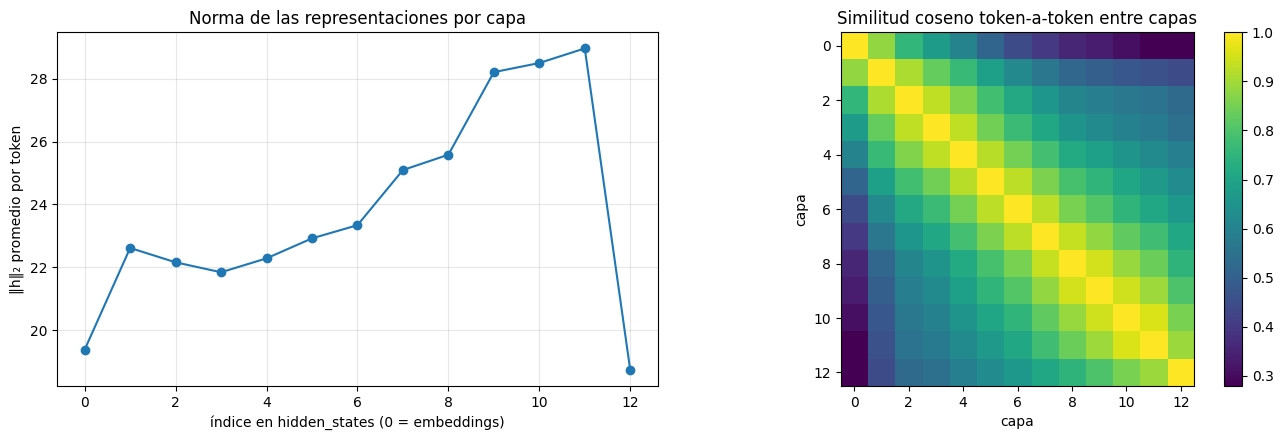

In [ ]:
hs = torch.stack([h[0].float().cpu() for h in hidden_states])      # [13, seq_len, 768]
L = hs.shape[1]

# (a) norma L2 promedio por capa
normas = hs.norm(dim=-1).mean(dim=1)

# (b) similitud coseno token a token entre capas i y j, promediada sobre los tokens
hn = torch.nn.functional.normalize(hs, dim=-1)
sim = torch.einsum("itd,jtd->ij", hn, hn) / L

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(range(13), normas.numpy(), marker="o")
ax[0].set_xlabel("índice en hidden_states (0 = embeddings)"); ax[0].set_ylabel("‖h‖₂ promedio por token")
ax[0].set_title("Norma de las representaciones por capa"); ax[0].grid(alpha=.3)
im = ax[1].imshow(sim.numpy(), cmap="viridis")
ax[1].set_title("Similitud coseno token-a-token entre capas")
ax[1].set_xlabel("capa"); ax[1].set_ylabel("capa"); plt.colorbar(im, ax=ax[1], fraction=.046)
plt.tight_layout(); plt.show()

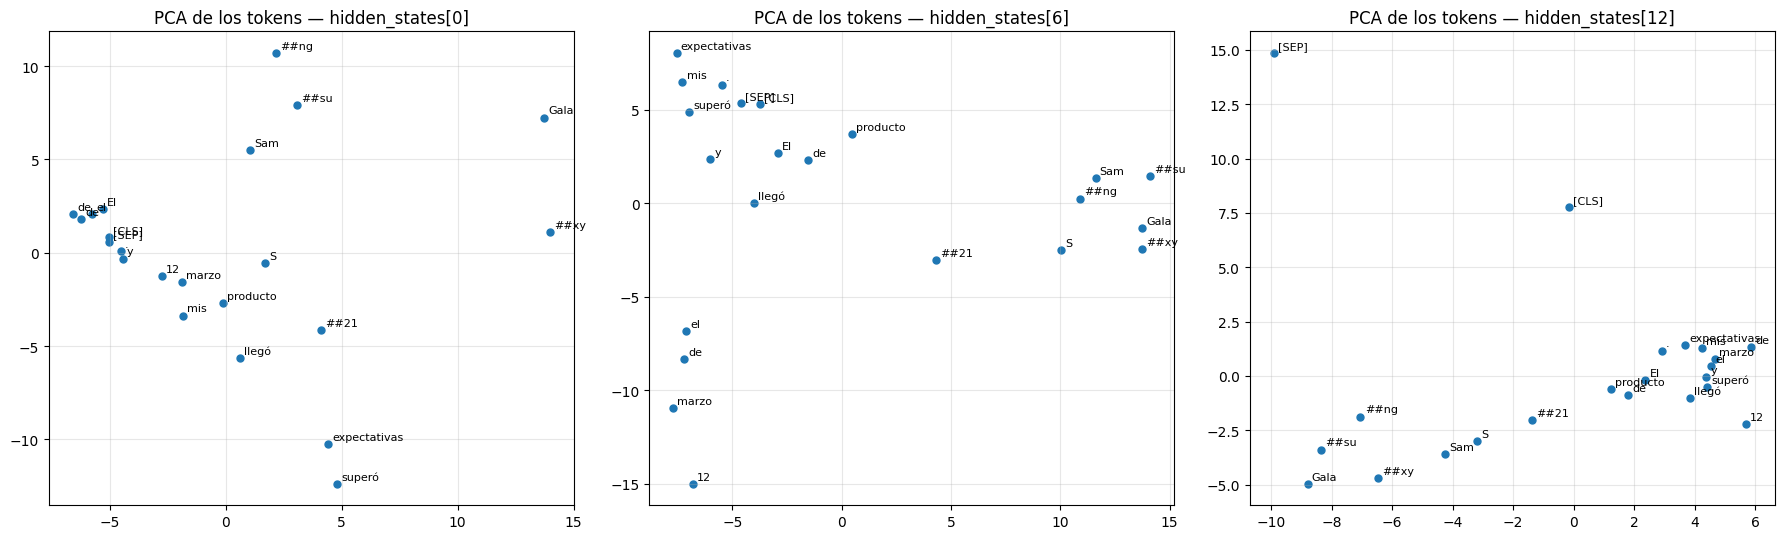

In [ ]:
def pca2(X):
    X = X - X.mean(0, keepdim=True)
    _, _, Vh = torch.linalg.svd(X, full_matrices=False)
    return (X @ Vh[:2].T).numpy()

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, l in zip(axes, [0, 6, 12]):
    p = pca2(hs[l])
    ax.scatter(p[:, 0], p[:, 1], s=25)
    for (x_, y_), t in zip(p, tokens):
        ax.annotate(t, (x_, y_), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"PCA de los tokens — hidden_states[{l}]"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 📝 Análisis — Sección 2

**1. El diccionario `inputs`**

- **`input_ids`**: tensor `[1, L]` de enteros. Cada entero es el índice, en el vocabulario de BETO, del *token WordPiece* correspondiente. El tokenizador (a) separa el texto en palabras y subpalabras (las que no están completas en el vocabulario se parten con el prefijo `##`, por eso hay más tokens que palabras: nombres como «Samsung» o «Galaxy» y números como «S21» suelen fragmentarse), y (b) añade los tokens especiales `[CLS]` al inicio y `[SEP]` al final. Estos ids son la entrada de `word_embeddings`.
- **`token_type_ids`**: *segment ids*. Indican a qué segmento pertenece cada token (0 = primera oración/segmento A, 1 = segunda/segmento B) y alimentan `token_type_embeddings`. BERT se diseñó para tareas con pares de oraciones (NSP, inferencia, preguntas-respuestas). Con una sola oración **todos son 0**, como se ve en la tabla; en la celda del par de oraciones se observa el cambio a 1.
- **`attention_mask`**: indica qué posiciones son tokens reales (1) y cuáles son relleno `[PAD]` (0). Está compuesta solo por **unos** porque procesamos **una única oración, sin *padding***: todos los tokens son reales y deben ser atendidos. Cuando se agrupan oraciones de distinto largo en un lote (celda de *padding*), las oraciones cortas se completan con `[PAD]` y su máscara tiene ceros; internamente la máscara se convierte en una máscara aditiva (0 para atender, un valor muy negativo para ignorar) que se suma a los scores antes del softmax, de modo que los `[PAD]` reciben probabilidad ≈ 0.

**2. ¿Por qué `len(hidden_states)` = 13 con 12 capas?**

`hidden_states` es una tupla con la salida de **cada etapa** del modelo, no solo de los bloques del encoder. La posición **0** es la **salida de la capa de embeddings** (embedding de palabra + posición + segmento, con LayerNorm y dropout): es el tensor que entra al primer `BertLayer`. Las posiciones **1 a 12** son las salidas de los 12 bloques codificadores; la **12** coincide exactamente con `last_hidden_state`. Así, 1 (embeddings) + 12 (encoders) = **13**. Lo verificamos con código: `hidden_states[0]` es idéntico a `model.embeddings(...)`, `hidden_states[12]` a `last_hidden_state`, y aplicar `model.encoder.layer[i]` a mano reproduce cada tensor intermedio.

**3. `hidden_states[0].shape` → `[batch_size, sequence_length, hidden_size]`**

- **`batch_size` (=1)**: número de oraciones procesadas en paralelo; aquí una sola.
- **`sequence_length` (=L, el valor impreso arriba)**: número de tokens WordPiece de la entrada, **incluyendo `[CLS]` y `[SEP]`**. Es mayor que el número de palabras por la subtokenización. Es la única dimensión que cambia con el texto (máximo 512 por las posiciones aprendidas; aquí truncamos a 128).
- **`hidden_size` (=768)**: dimensión del vector que representa a cada token ($d_{model}$). Es la misma en los 13 tensores: los bloques de BERT conservan la forma de entrada, lo que hace posibles las conexiones residuales.

**Lectura de los gráficos:** las capas bajas conservan información léxica/superficial del token (similitud alta entre capas vecinas) y las altas lo contextualizan cada vez más con el resto de la oración. La proyección PCA muestra que la geometría de los tokens cambia entre embeddings, capa 6 y capa 12.

---
## 3) Diagrama Conceptual y Pseudocódigo 🙌

Pseudocódigo del mecanismo de Self-Attention

## Diagrama Conceptual — Self-Attention dentro de BETO

![Diagrama conceptual del bloque BertLayer y de una cabeza de atención](attachment:diagrama_bertlayer.png)

*Izquierda: bloque `BertLayer` completo con sus dos conexiones residuales. Derecha: cálculo de **una** cabeza de atención con las formas de los tensores ($d_{model}=768$, 12 cabezas, $d_k=64$).*

### Diagrama conceptual (código que lo genera)

La celda siguiente dibuja la misma figura con `matplotlib`; Izquierda: el bloque `BertLayer` completo con sus dos conexiones residuales. Derecha: el detalle del cálculo de **una** cabeza de atención con las formas de los tensores (las dimensiones se leen de `config`).

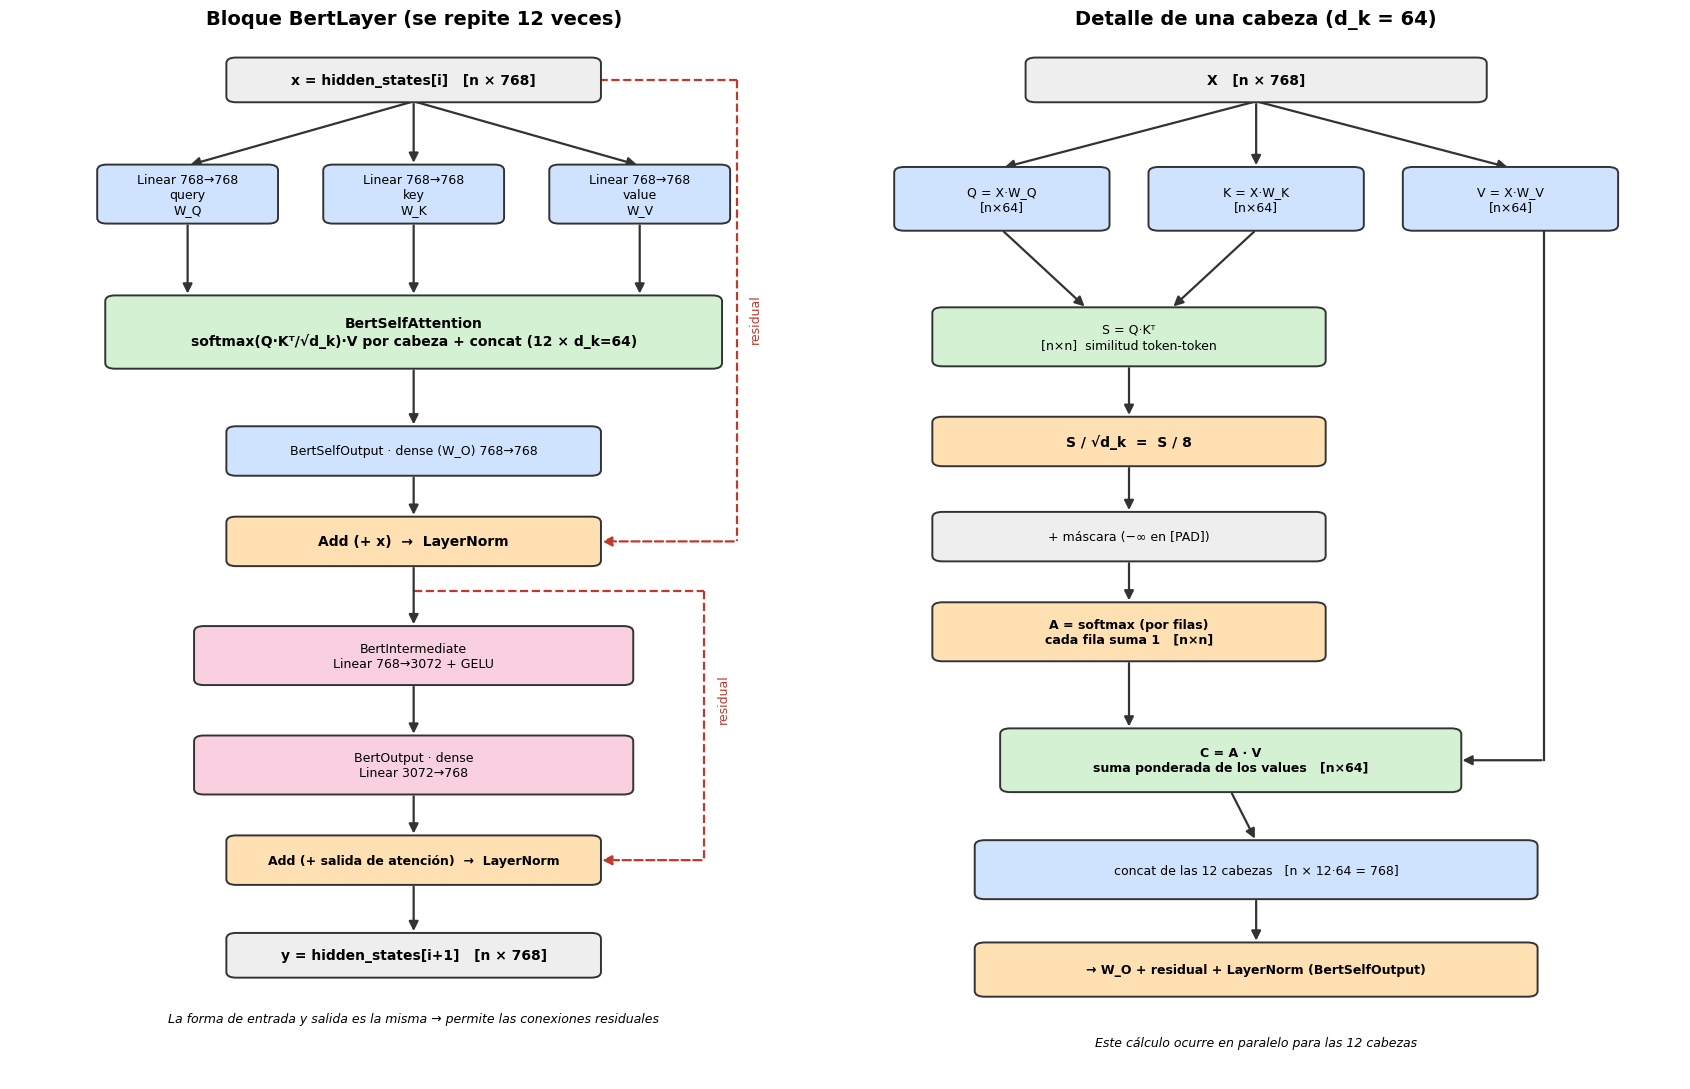

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc, ec="#333", fs=10, bold=False):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=fc, ec=ec, lw=1.4, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, zorder=4,
            fontweight="bold" if bold else "normal")

def arrow(ax, p0, p1, color="#333", style="-|>", ls="-", rad=0.0, lw=1.6):
    ax.add_patch(FancyArrowPatch(p0, p1, arrowstyle=style, mutation_scale=14, lw=lw, color=color,
                                 linestyle=ls, connectionstyle=f"arc3,rad={rad}", zorder=2))

def draw_bert_layer_diagram(n_label="n", d_model=768, heads=12, d_ff=3072):
    dk = d_model // heads
    BLUE, GREEN, ORANGE, GRAY, PINK = "#cfe3ff", "#d4f1d4", "#ffe0b3", "#eeeeee", "#f8d0e0"
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 11), gridspec_kw={"width_ratios": [1, 1.05]})

    # ───────── Panel izquierdo: BertLayer completo ─────────
    ax = ax1; ax.set_xlim(0, 10); ax.set_ylim(0, 22); ax.axis("off")
    ax.set_title("Bloque BertLayer (se repite 12 veces)", fontsize=14, fontweight="bold")
    box(ax, 5, 21, 4.6, 0.9, f"x = hidden_states[i]   [{n_label} × {d_model}]", GRAY, bold=True)
    for xq, nm in [(2.2, "query\nW_Q"), (5, "key\nW_K"), (7.8, "value\nW_V")]:
        box(ax, xq, 18.6, 2.2, 1.2, f"Linear {d_model}→{d_model}\n{nm}", BLUE, fs=9)
        arrow(ax, (5, 20.55), (xq, 19.2))
    box(ax, 5, 15.7, 7.6, 1.5,
        f"BertSelfAttention\nsoftmax(Q·Kᵀ/√d_k)·V por cabeza + concat ({heads} × d_k={dk})", GREEN, fs=10, bold=True)
    for xq in (2.2, 5, 7.8): arrow(ax, (xq, 18.0), (xq if xq != 5 else 5, 16.45))
    box(ax, 5, 13.2, 4.6, 1.0, f"BertSelfOutput · dense (W_O) {d_model}→{d_model}", BLUE, fs=9)
    arrow(ax, (5, 14.95), (5, 13.7))
    box(ax, 5, 11.3, 4.6, 1.0, "Add (+ x)  →  LayerNorm", ORANGE, bold=True)
    arrow(ax, (5, 12.7), (5, 11.8))
    # residual 1
    ax.plot([9.0, 9.0], [21, 11.3], color="#c0392b", lw=1.6, ls="--", zorder=1)
    ax.plot([5.7, 9.0], [21, 21], color="#c0392b", lw=1.6, ls="--", zorder=1)
    arrow(ax, (9.0, 11.3), (7.3, 11.3), color="#c0392b", ls="--")
    ax.text(9.15, 16, "residual", rotation=90, color="#c0392b", va="center", fontsize=9)
    box(ax, 5, 8.9, 5.4, 1.2, f"BertIntermediate\nLinear {d_model}→{d_ff} + GELU", PINK, fs=9)
    arrow(ax, (5, 10.8), (5, 9.5))
    box(ax, 5, 6.6, 5.4, 1.2, f"BertOutput · dense\nLinear {d_ff}→{d_model}", PINK, fs=9)
    arrow(ax, (5, 8.3), (5, 7.2))
    box(ax, 5, 4.6, 4.6, 1.0, "Add (+ salida de atención)  →  LayerNorm", ORANGE, bold=True, fs=9)
    arrow(ax, (5, 6.0), (5, 5.1))
    # residual 2
    ax.plot([8.6, 8.6], [10.25, 4.6], color="#c0392b", lw=1.6, ls="--", zorder=1)
    ax.plot([5, 8.6], [10.25, 10.25], color="#c0392b", lw=1.6, ls="--", zorder=1)
    arrow(ax, (8.6, 4.6), (7.3, 4.6), color="#c0392b", ls="--")
    ax.text(8.75, 8, "residual", rotation=90, color="#c0392b", va="center", fontsize=9)
    box(ax, 5, 2.6, 4.6, 0.9, f"y = hidden_states[i+1]   [{n_label} × {d_model}]", GRAY, bold=True)
    arrow(ax, (5, 4.1), (5, 3.05))
    ax.text(5, 1.2, "La forma de entrada y salida es la misma → permite las conexiones residuales",
            ha="center", fontsize=9, style="italic")

    # ───────── Panel derecho: atención escalada por producto punto ─────────
    ax = ax2; ax.set_xlim(0, 10); ax.set_ylim(0, 22); ax.axis("off")
    ax.set_title(f"Detalle de una cabeza (d_k = {dk})", fontsize=14, fontweight="bold")
    box(ax, 5, 21, 5.4, 0.9, f"X   [{n_label} × {d_model}]", GRAY, bold=True)
    for xq, nm, sh in [(2, "Q = X·W_Q", f"[{n_label}×{dk}]"), (5, "K = X·W_K", f"[{n_label}×{dk}]"), (8, "V = X·W_V", f"[{n_label}×{dk}]")]:
        box(ax, xq, 18.5, 2.5, 1.3, f"{nm}\n{sh}", BLUE, fs=9)
        arrow(ax, (5, 20.55), (xq, 19.15))
    box(ax, 3.5, 15.6, 4.6, 1.2, f"S = Q·Kᵀ\n[{n_label}×{n_label}]  similitud token-token", GREEN, fs=9)
    arrow(ax, (2, 17.85), (3.0, 16.2)); arrow(ax, (5, 17.85), (4.0, 16.2))
    box(ax, 3.5, 13.4, 4.6, 1.0, f"S / √d_k  =  S / {int(dk**0.5)}", ORANGE, fs=10, bold=True)
    arrow(ax, (3.5, 15.0), (3.5, 13.9))
    box(ax, 3.5, 11.4, 4.6, 1.0, "+ máscara (−∞ en [PAD])", GRAY, fs=9)
    arrow(ax, (3.5, 12.9), (3.5, 11.9))
    box(ax, 3.5, 9.4, 4.6, 1.2, f"A = softmax (por filas)\ncada fila suma 1   [{n_label}×{n_label}]", ORANGE, fs=9, bold=True)
    arrow(ax, (3.5, 10.9), (3.5, 10.0))
    box(ax, 4.7, 6.7, 5.4, 1.3, f"C = A · V\nsuma ponderada de los values   [{n_label}×{dk}]", GREEN, fs=9, bold=True)
    arrow(ax, (3.5, 8.8), (3.5, 7.35))
    ax.plot([8.4, 8.4], [17.85, 6.7], color="#333", lw=1.6, zorder=1); arrow(ax, (8.4, 6.7), (7.4, 6.7))
    box(ax, 5, 4.4, 6.6, 1.2, f"concat de las {heads} cabezas   [{n_label} × {heads}·{dk} = {d_model}]", BLUE, fs=9)
    arrow(ax, (4.7, 6.05), (5, 5.0))
    box(ax, 5, 2.3, 6.6, 1.1, "→ W_O + residual + LayerNorm (BertSelfOutput)", ORANGE, fs=9, bold=True)
    arrow(ax, (5, 3.8), (5, 2.85))
    ax.text(5, 0.7, f"Este cálculo ocurre en paralelo para las {heads} cabezas", ha="center", fontsize=9, style="italic")
    plt.tight_layout()
    return fig

# Autosuficiente: usa `config` si existe; si no, los valores de BETO (768 / 12 cabezas / 3072)
_cfg = globals().get("config")
fig = draw_bert_layer_diagram(n_label="n",
                              d_model=getattr(_cfg, "hidden_size", 768),
                              heads=getattr(_cfg, "num_attention_heads", 12),
                              d_ff=getattr(_cfg, "intermediate_size", 3072))
plt.show()

### Diagrama conceptual del bloque `BertLayer` (versión en texto)

```
                  x  [n × 768]   (hidden_states[i])
                  │
      ┌───────────┼───────────────┬───────────────┐
      ▼           ▼               ▼               │ (conexión residual)
   Linear Wq   Linear Wk       Linear Wv          │
      │           │               │               │
      Q           K               V      ← [n×768] = 12 cabezas × 64
      └───┬───────┘               │               │
          ▼                       │               │
   scores = Q·Kᵀ / √d_k  (+ máscara)  [12 × n × n]│
          ▼                       │               │
     softmax (por filas) ─────────┤               │
          ▼                       ▼               │
          └────────►  A · V  (suma ponderada)     │   ← BertSelfAttention
                      │  concat de las 12 cabezas │
                      ▼                           │
              Linear W_O (dense)                  │   ← BertSelfOutput
                      ▼                           │
                 ( + x ) ◄────────────────────────┘
                      ▼
                 LayerNorm  ───────────────┐
                      ▼                    │ (residual)
        Linear 768→3072 + GELU             │        ← BertIntermediate
                      ▼                    │
              Linear 3072→768              │        ← BertOutput
                      ▼                    │
                 ( + ) ◄───────────────────┘
                      ▼
                 LayerNorm
                      ▼
                  y  [n × 768]   (hidden_states[i+1])
```

### Pseudocódigo paso a paso de Self-Attention multi-cabeza

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^{T}}{\sqrt{d_k}}\right)V$$

```text
ENTRADA : X ∈ R^(n × d_model)       # n tokens, d_model = 768  (hidden_states[i])
          M ∈ {0,1}^n                # attention_mask
PARÁMETROS : W_Q, W_K, W_V ∈ R^(768 × 768) y sus sesgos b_Q, b_K, b_V
             h = 12 cabezas ; d_k = d_model / h = 64

1. PROYECCIÓN LINEAL (una por cada rol del token)
      Q ← X · W_Q + b_Q            # "qué busco"          [n × 768]
      K ← X · W_K + b_K            # "qué ofrezco"        [n × 768]
      V ← X · W_V + b_V            # "qué información doy" [n × 768]

2. DIVIDIR EN CABEZAS
      reorganizar Q, K, V de [n × 768] a [h × n × d_k]     # [12 × n × 64]

3. PARA CADA CABEZA j = 1..h  (en paralelo):
   3.1  S_j ← Q_j · K_jᵀ                  # similitud token-token      [n × n]
   3.2  S_j ← S_j / √d_k                  # escalar: evita softmax saturado (√64 = 8)
   3.3  S_j[:, p] ← −∞  si M[p] = 0       # ignorar los [PAD]
   3.4  A_j ← softmax(S_j) por filas      # cada fila suma 1 → pesos de atención
   3.5  A_j ← dropout(A_j)                # solo en entrenamiento
   3.6  C_j ← A_j · V_j                   # suma ponderada de los values   [n × 64]

4. CONCATENAR LAS CABEZAS
      C ← concat(C_1, ..., C_h)           # [n × 768]

5. PROYECCIÓN DE SALIDA + RESIDUAL + NORMALIZACIÓN   (BertSelfOutput)
      O ← LayerNorm( C · W_O + b_O + X )  # [n × 768]

6. FEED-FORWARD + RESIDUAL + NORMALIZACIÓN           (BertIntermediate + BertOutput)
      Y ← LayerNorm( GELU(O · W_1 + b_1) · W_2 + b_2 + O )   # [n × 768] = hidden_states[i+1]

SALIDA : Y ∈ R^(n × 768)
```

**Lo que hace cada operación**

- *Proyección lineal:* el mismo vector $x_t$ de cada token se transforma en tres vectores distintos: consulta $q_t$, clave $k_t$ y valor $v_t$.
- *$QK^T$:* el producto punto $q_t\cdot k_s$ mide cuánto debe «mirar» el token $t$ al token $s$ (matriz $n\times n$).
- *División por $\sqrt{d_k}$:* con $d_k$ grande los productos punto crecen en magnitud (varianza $\approx d_k$) y el softmax se satura (gradientes casi nulos); dividir mantiene la varianza ≈ 1.
- *Softmax por filas:* convierte los scores de cada token en una distribución de probabilidad sobre todos los tokens (atención **bidireccional**: BERT mira a izquierda y derecha, no hay máscara causal).
- *Suma ponderada con $V$:* el nuevo vector de cada token es la mezcla de los *values* de todos los tokens, ponderada por esas probabilidades.
- *Multi-cabeza:* varias atenciones en paralelo en subespacios de 64 dimensiones permiten captar relaciones distintas (sintácticas, de posición, de correferencia…); $W^O$ las vuelve a mezclar.

**Ejemplo numérico mínimo** (3 tokens, $d_{model}=d_k=4$, una sola cabeza) para ver cada paso del pseudocódigo con números pequeños:

In [ ]:
np.set_printoptions(precision=3, suppress=True)
rng = np.random.default_rng(0)
n, d = 3, 4
X  = rng.normal(size=(n, d))                     # 3 tokens, 4 dimensiones
Wq, Wk, Wv = (rng.normal(size=(d, d)) for _ in range(3))

Q, K, V = X @ Wq, X @ Wk, X @ Wv                 # Paso 1: proyecciones lineales
S  = Q @ K.T                                     # Paso 3.1: scores [n×n]
Ss = S / np.sqrt(d)                              # Paso 3.2: escalado
A  = np.exp(Ss - Ss.max(1, keepdims=True)); A /= A.sum(1, keepdims=True)   # Paso 3.4: softmax por filas
C  = A @ V                                       # Paso 3.6: suma ponderada con V

print("Q =\n", Q, "\n\nQ·Kᵀ =\n", S, "\n\nQ·Kᵀ/√d_k =\n", Ss)
print("\nA = softmax(...) =\n", A, "\nSuma por filas:", A.sum(1))
print("\nSalida A·V =\n", C)
assert np.allclose(A.sum(1), 1.0)

Q =
 [[-0.208  0.899 -0.715 -0.101]
 [ 1.737  1.874 -0.755  0.355]
 [ 2.442 -0.294  0.74  -1.061]] 

Q·Kᵀ =
 [[-0.296 -0.788 -0.691]
 [-0.986 -1.874 -0.208]
 [-2.107 -5.881  3.63 ]] 

Q·Kᵀ/√d_k =
 [[-0.148 -0.394 -0.346]
 [-0.493 -0.937 -0.104]
 [-1.053 -2.94   1.815]]

A = softmax(...) =
 [[0.384 0.3   0.315]
 [0.321 0.206 0.473]
 [0.053 0.008 0.939]] 
Suma por filas: [1. 1. 1.]

Salida A·V =
 [[-0.56   0.181 -1.578 -0.293]
 [-1.022 -0.329 -1.314 -0.198]
 [-2.297 -1.679 -0.751 -0.098]]


**Implementación en PyTorch** (multi-cabeza, con máscara) y verificación contra las capas reales de BETO:

In [ ]:
def my_self_attention(x, Wq, bq, Wk, bk, Wv, bv, num_heads, attention_mask=None):
    # Self-Attention multi-cabeza escrita desde cero. x: [B, n, d_model]
    B, n, D = x.shape
    dk = D // num_heads
    q = x @ Wq.T + bq                                           # Paso 1
    k = x @ Wk.T + bk
    v = x @ Wv.T + bv
    split = lambda t: t.view(B, n, num_heads, dk).transpose(1, 2)   # Paso 2: [B, h, n, dk]
    q, k, v = split(q), split(k), split(v)
    scores = q @ k.transpose(-2, -1)                            # Paso 3.1: [B, h, n, n]
    scores = scores / math.sqrt(dk)                             # Paso 3.2
    if attention_mask is not None:                              # Paso 3.3
        scores = scores.masked_fill(attention_mask[:, None, None, :] == 0, torch.finfo(scores.dtype).min)
    probs = torch.softmax(scores, dim=-1)                       # Paso 3.4
    ctx = (probs @ v).transpose(1, 2).reshape(B, n, D)          # Pasos 3.6 y 4
    return ctx, probs


@torch.no_grad()
def my_bert_layer(layer, x, attention_mask, num_heads):
    # Un BertLayer completo reconstruido con nuestras funciones (modo eval: sin dropout).
    sa = layer.attention.self
    ctx, probs = my_self_attention(x, sa.query.weight, sa.query.bias, sa.key.weight, sa.key.bias,
                                   sa.value.weight, sa.value.bias, num_heads, attention_mask)
    o = layer.attention.output.LayerNorm(layer.attention.output.dense(ctx) + x)      # Paso 5
    inter = layer.intermediate(o)                                                    # Paso 6: 768→3072 + GELU
    y = layer.output.LayerNorm(layer.output.dense(inter) + o)                        # Paso 6: 3072→768 + residual + LN
    return y, probs

In [ ]:
# Pesos de atención reales de BETO (requiere attn_implementation="eager", ya configurado)
with torch.no_grad():
    out_att = model(**inputs, output_attentions=True)
attentions = out_att.attentions
assert attentions is not None and len(attentions) == config.num_hidden_layers, \
    "No se obtuvieron atenciones: recarga el modelo con attn_implementation='eager'"
print("attentions:", len(attentions), "tensores de forma", tuple(attentions[0].shape), "→ [batch, heads, n, n]")

# Verificación: nuestras funciones reproducen las 12 capas de BETO
rows = []
for i, layer in enumerate(model.encoder.layer):
    y, probs = my_bert_layer(layer, hidden_states[i], inputs["attention_mask"], config.num_attention_heads)
    d_out   = (y - hidden_states[i + 1]).abs().max().item()
    d_probs = (probs - attentions[i]).abs().max().item()
    rows.append((i + 1, d_probs, d_out))
    assert d_probs < 1e-3 and d_out < 1e-3, f"Capa {i+1}: diferencia excesiva"
    assert torch.allclose(probs.sum(-1), torch.ones_like(probs.sum(-1)), atol=1e-4)   # filas suman 1
display(pd.DataFrame(rows, columns=["capa", "max|A_nuestra − A_BERT|", "max|salida_nuestra − hidden_states[i]|"])
          .set_index("capa").style.format("{:.2e}"))
print("✅ Nuestra implementación de Self-Attention + Add&Norm + FFN reproduce las 12 capas de BETO.")

attentions: 12 tensores de forma (1, 12, 22, 22) → [batch, heads, n, n]


,max|A_nuestra − A_BERT|,max|salida_nuestra − hidden_states[i]|
capa,,
1,5.07e-07,9.54e-07
2,7.15e-07,1.91e-06
3,5.22e-07,9.54e-07
4,6.56e-07,1.43e-06
5,5.96e-07,1.91e-06
6,6.56e-07,2.86e-06
7,5.36e-07,1.91e-06
8,6.85e-07,1.91e-06
9,6.56e-07,1.91e-06


✅ Nuestra implementación de Self-Attention + Add&Norm + FFN reproduce las 12 capas de BETO.


**Visualización de los pesos de atención** — las 12 cabezas de la primera y de la última capa (filas = token que consulta, columnas = token atendido):

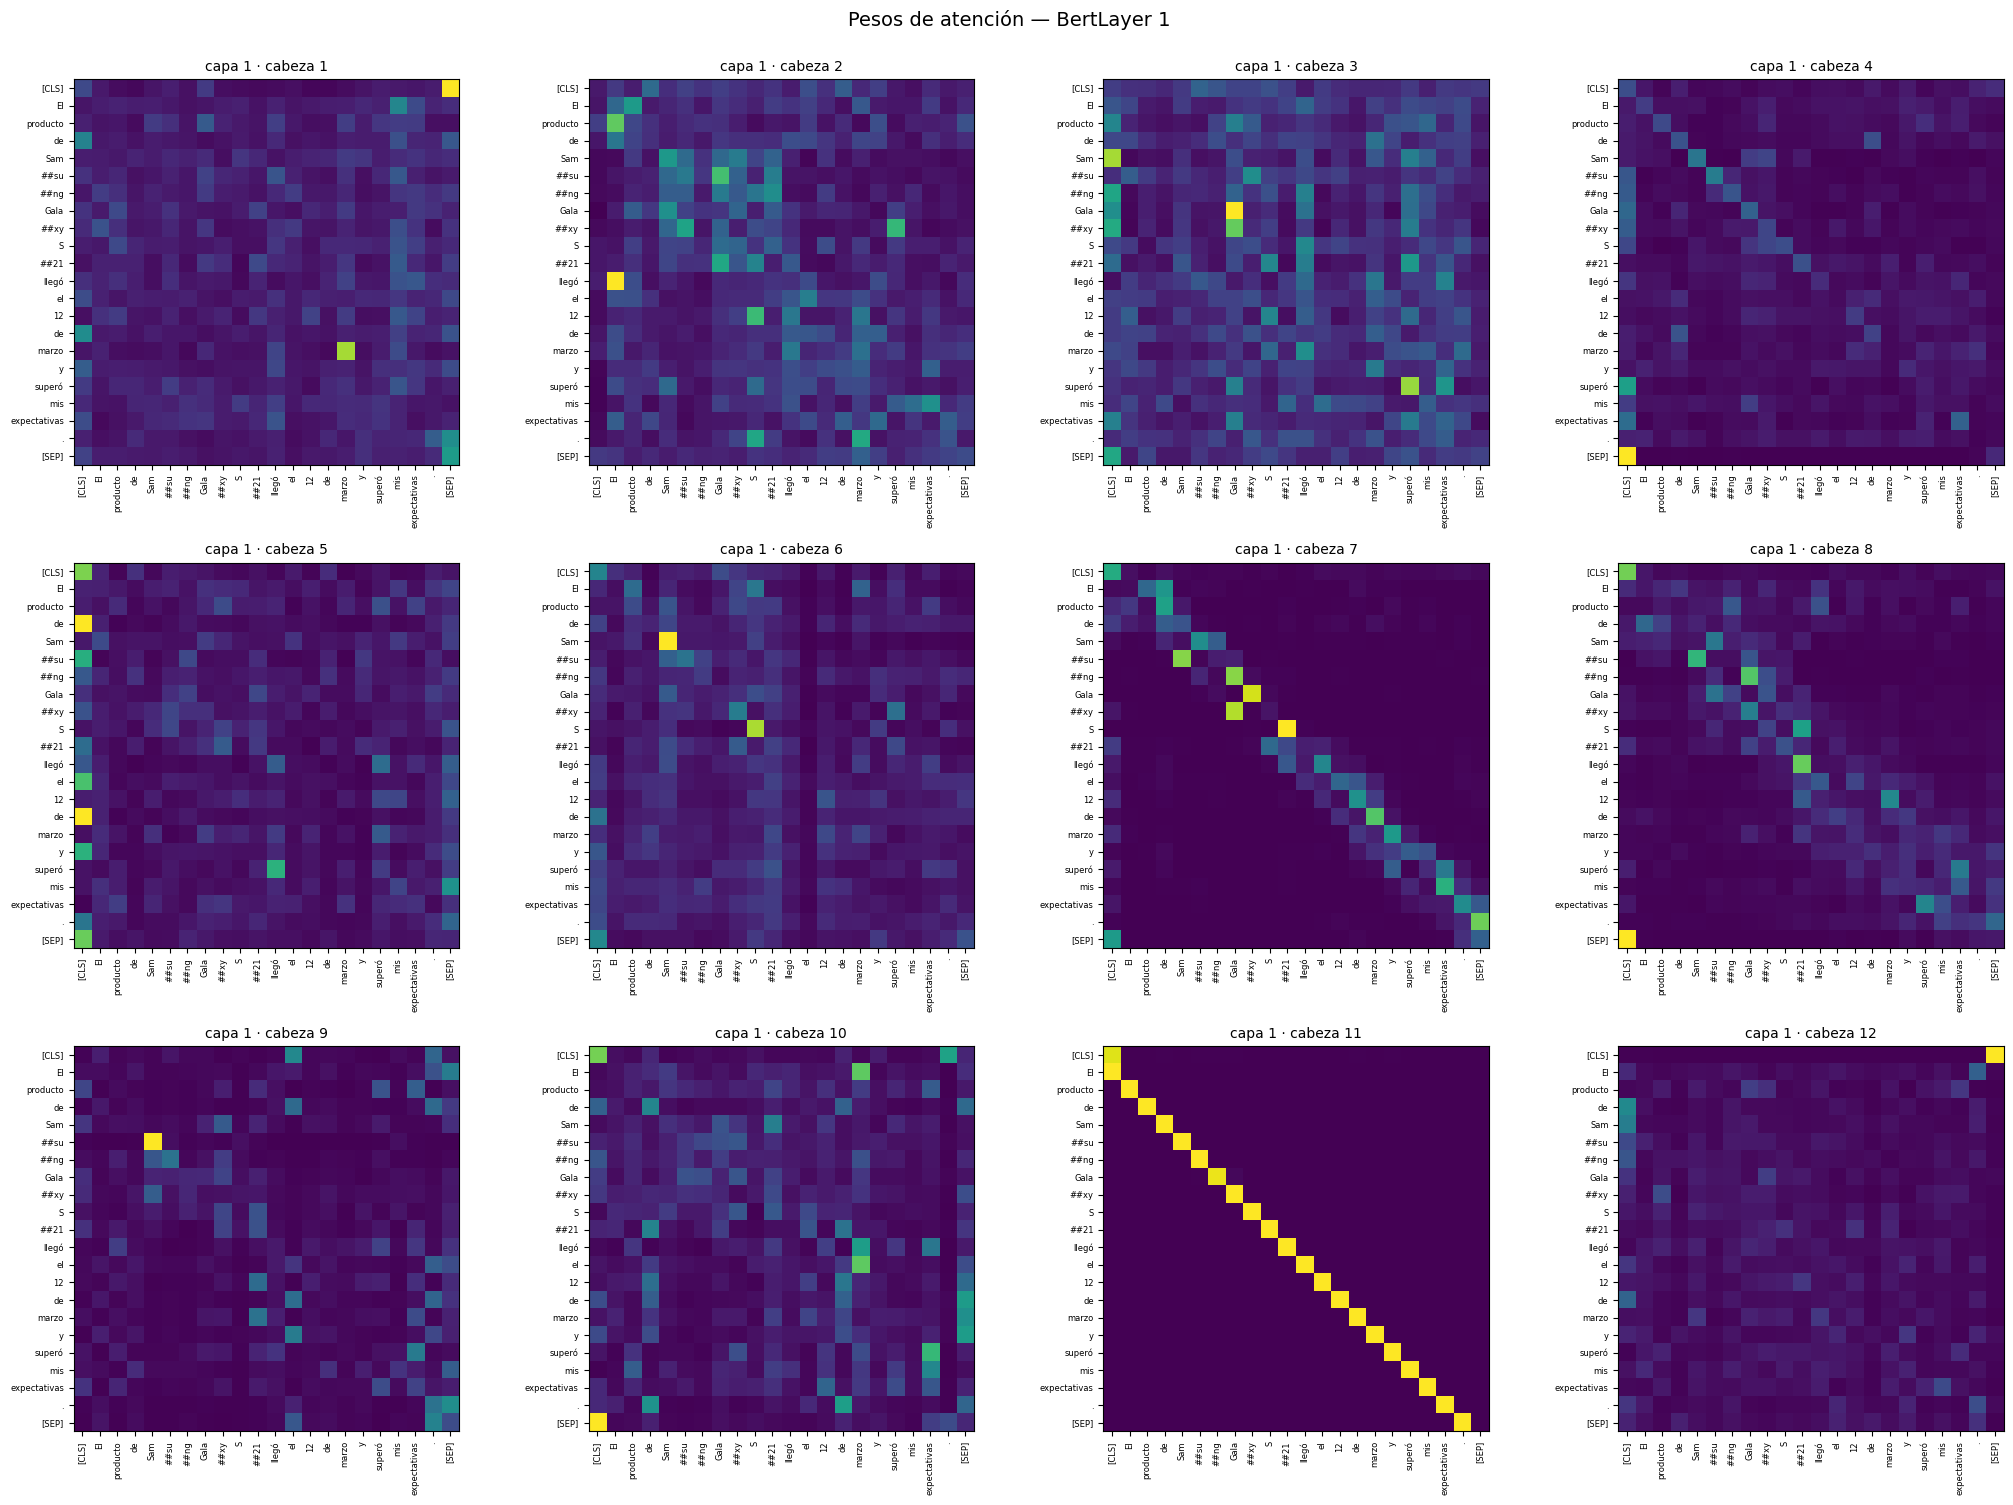

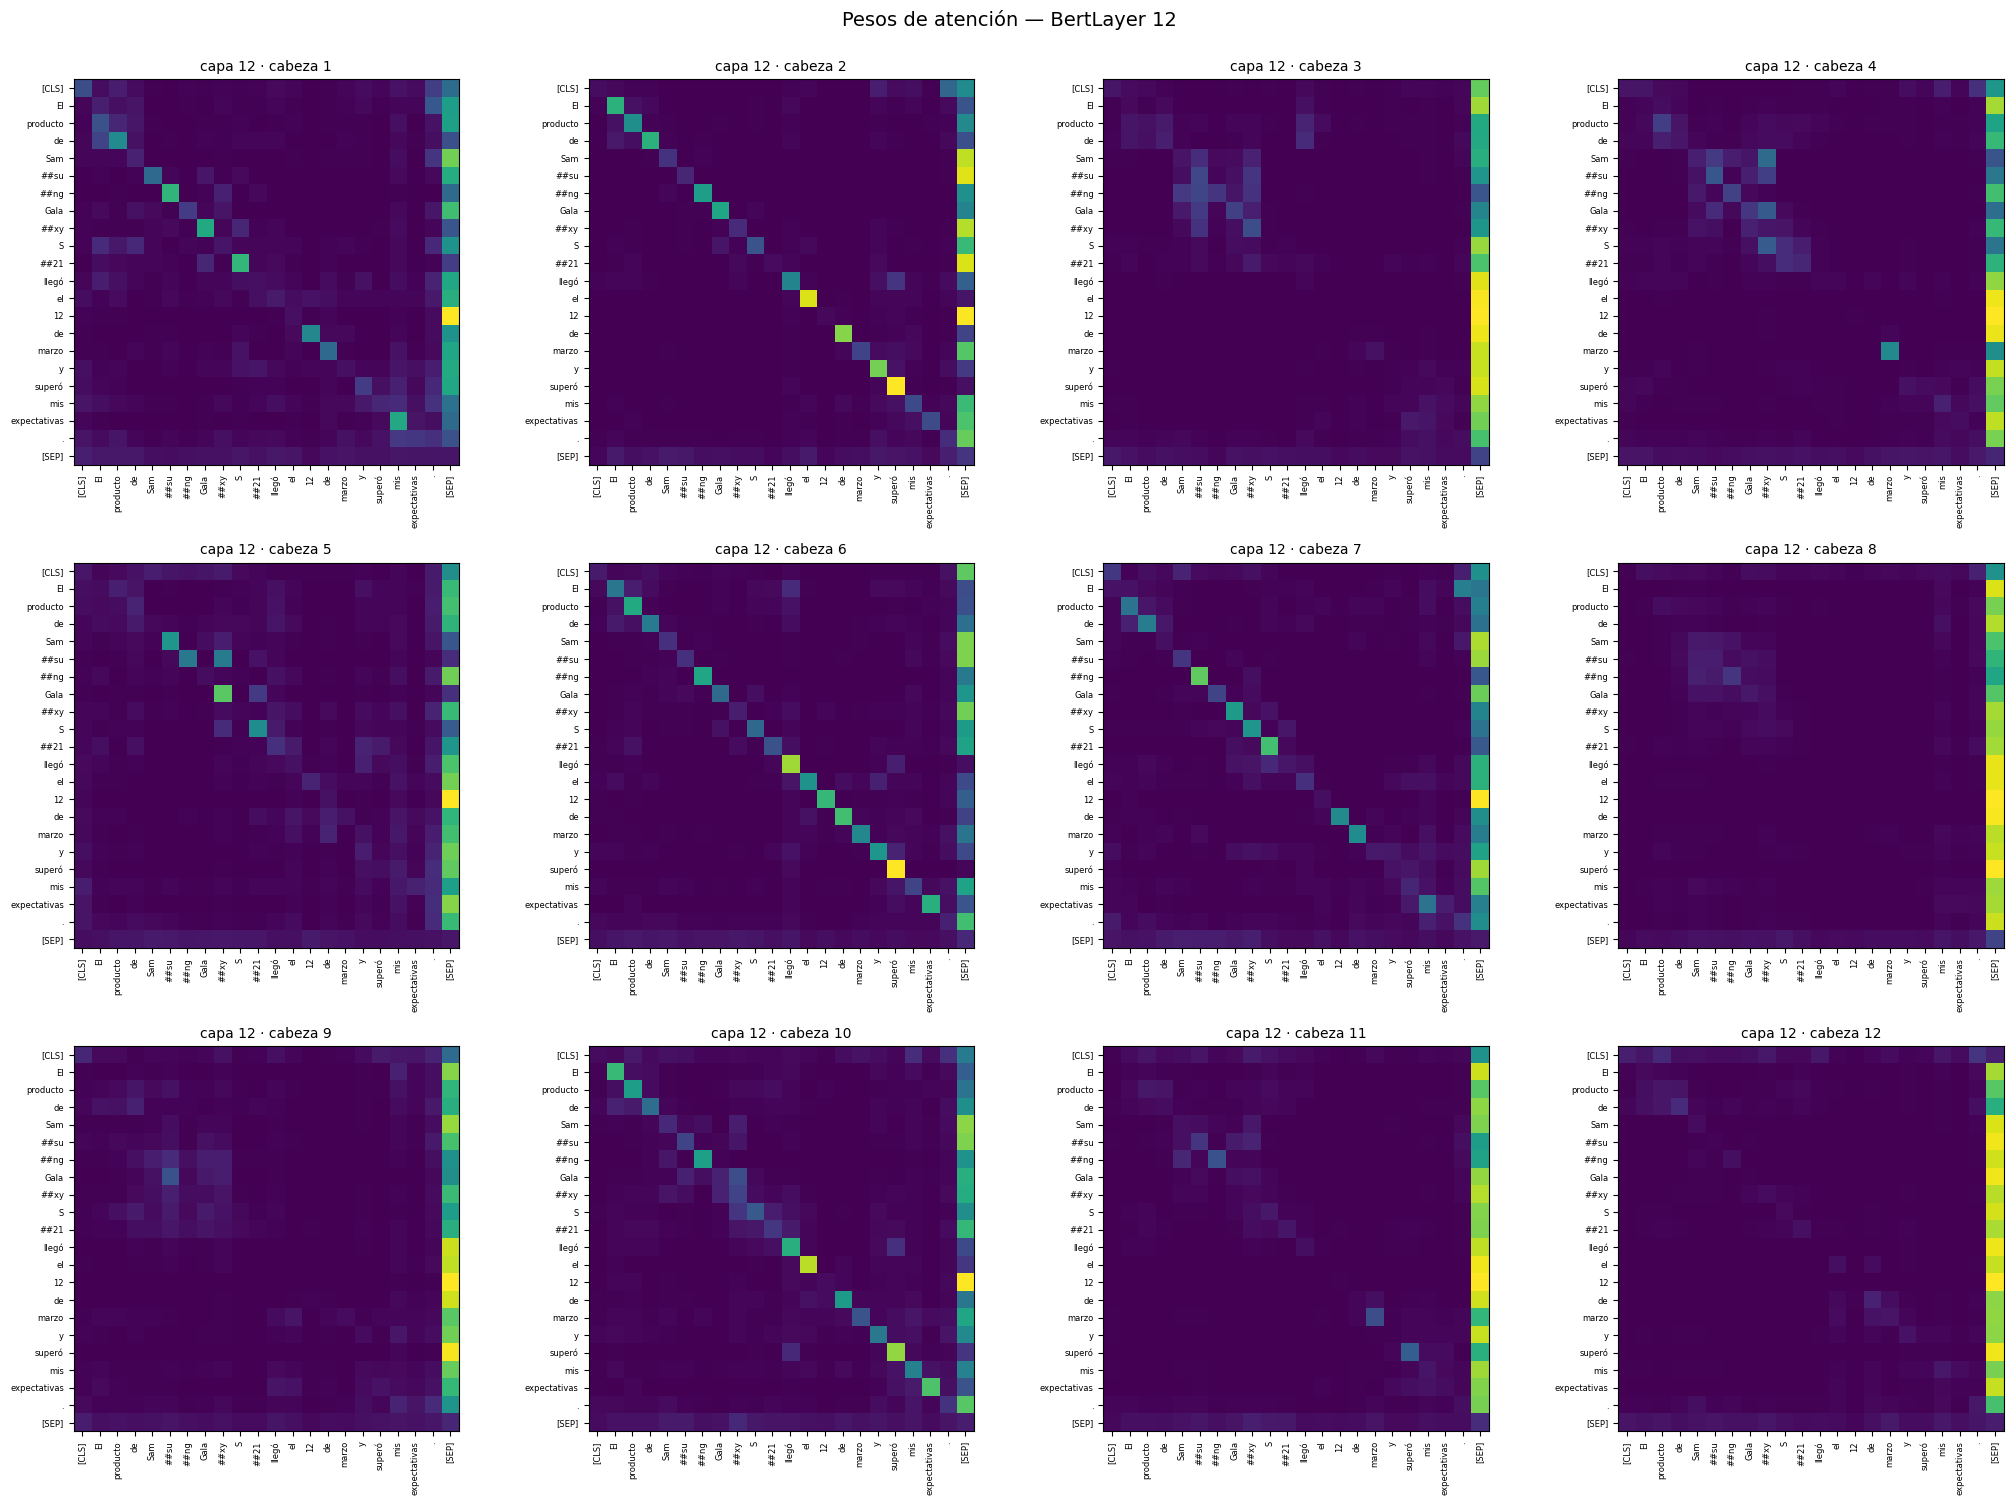

In [ ]:
def plot_heads(layer_idx, cols=4):
    att = attentions[layer_idx][0].float().cpu().numpy()          # [heads, n, n]
    H = att.shape[0]; rows = math.ceil(H / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(5.2 * cols, 5.0 * rows))
    for h, ax in enumerate(np.atleast_1d(axes).ravel()):
        ax.imshow(att[h], cmap="viridis", vmin=0)
        ax.set_xticks(range(len(tokens))); ax.set_yticks(range(len(tokens)))
        ax.set_xticklabels(tokens, rotation=90, fontsize=6); ax.set_yticklabels(tokens, fontsize=6)
        ax.set_title(f"capa {layer_idx + 1} · cabeza {h + 1}", fontsize=10)
    plt.suptitle(f"Pesos de atención — BertLayer {layer_idx + 1}", y=1.0, fontsize=14)
    plt.tight_layout(); plt.show()

plot_heads(0)
plot_heads(11)

**Atención promedio (sobre las 12 cabezas) de cada capa** — se ve cómo cambia el patrón de atención con la profundidad:

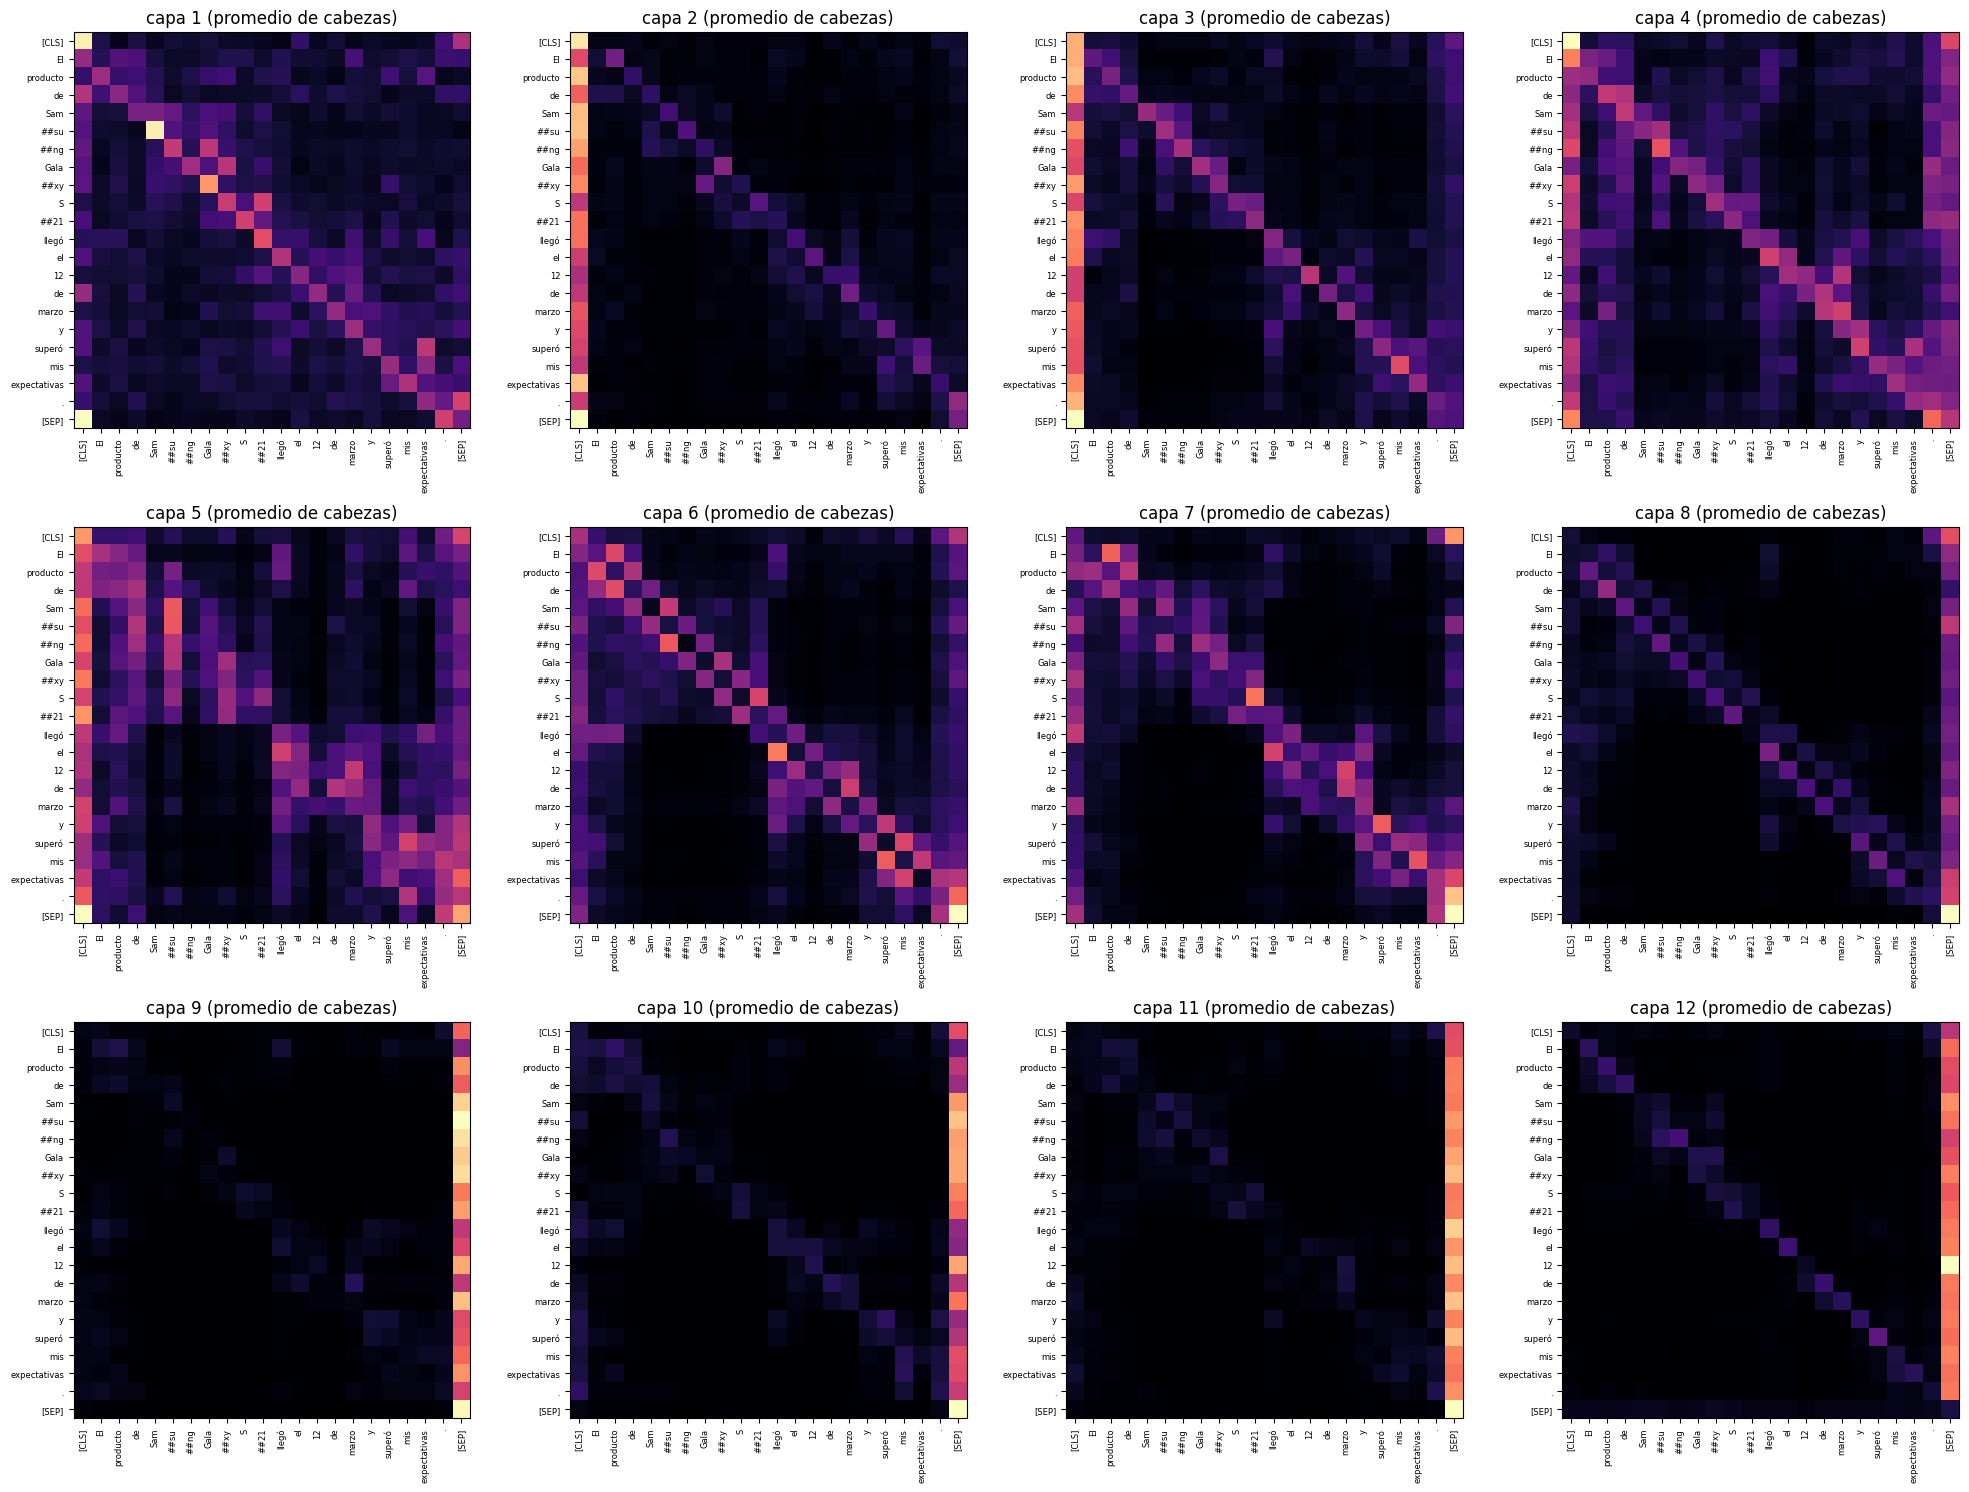

,tokens que más atención reciben
capa,
1,"[CLS] (0.10), [SEP] (0.06), ##21 (0.06)"
2,"[CLS] (0.40), [SEP] (0.05), superó (0.04)"
3,"[CLS] (0.28), [SEP] (0.07), . (0.06)"
4,"[CLS] (0.14), [SEP] (0.10), . (0.08)"
5,"[CLS] (0.15), [SEP] (0.10), . (0.07)"
6,"[SEP] (0.11), [CLS] (0.11), . (0.07)"
7,"[CLS] (0.12), [SEP] (0.12), . (0.06)"
8,"[SEP] (0.32), [CLS] (0.07), . (0.06)"
9,"[SEP] (0.66), El (0.03), producto (0.03)"


In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(20, 15))
for l, ax in enumerate(axes.ravel()):
    ax.imshow(attentions[l][0].float().mean(0).cpu().numpy(), cmap="magma", vmin=0)
    ax.set_xticks(range(len(tokens))); ax.set_yticks(range(len(tokens)))
    ax.set_xticklabels(tokens, rotation=90, fontsize=6); ax.set_yticklabels(tokens, fontsize=6)
    ax.set_title(f"capa {l + 1} (promedio de cabezas)")
plt.tight_layout(); plt.show()

# ¿A qué token atiende más, en promedio, cada capa? (excluyendo [CLS]/[SEP] del ranking)
filas = []
for l in range(12):
    colmean = attentions[l][0].float().mean(0).mean(0).cpu().numpy()    # atención recibida por token
    top = np.argsort(-colmean)[:3]
    filas.append((l + 1, ", ".join(f"{tokens[t]} ({colmean[t]:.2f})" for t in top)))
display(pd.DataFrame(filas, columns=["capa", "tokens que más atención reciben"]).set_index("capa"))

### 📝 Análisis — Sección 3

**1. Pseudocódigo del cálculo de Self-Attention**

Partimos de la entrada $X\in\mathbb{R}^{n\times 768}$ (los $n$ vectores de `hidden_states[i]`). El pseudocódigo completo, con formas de tensores, está al inicio de la sección; aquí se explica **cada operación en orden, desde la proyección lineal hasta la suma ponderada con $V$**:

1. **Proyección lineal:** cada token se multiplica por tres matrices aprendidas, $Q=XW_Q+b_Q$, $K=XW_K+b_K$, $V=XW_V+b_V$ (`query`, `key`, `value`). Es el mismo vector $x_t$ visto con tres «roles»: lo que *busca* ($q_t$), lo que *ofrece* para ser encontrado ($k_t$) y la *información* que aporta ($v_t$). Salida: tres tensores $[n\times 768]$.
2. **División en cabezas:** cada tensor se reorganiza de $[n\times 768]$ a $[12\times n\times 64]$. Cada cabeza trabaja en un subespacio de $d_k=64$ dimensiones y puede especializarse en un tipo de relación distinto.
3. **Scores $QK^T$:** el producto punto $q_t\cdot k_s$ mide la afinidad entre el token $t$ (que consulta) y el token $s$ (que es consultado). Resultado por cabeza: matriz $[n\times n]$.
4. **Escalado por $\sqrt{d_k}$:** si las componentes de $q$ y $k$ tienen varianza ≈ 1, el producto punto tiene varianza ≈ $d_k$; dividir por $\sqrt{64}=8$ la devuelve a ≈ 1 y evita que el softmax se sature (gradientes casi nulos).
5. **Máscara:** a los scores de las posiciones con `attention_mask = 0` ([PAD]) se les suma un valor muy negativo ($-\infty$), de modo que tras el softmax su peso es ≈ 0.
6. **Softmax por filas:** convierte cada fila de scores en pesos $\alpha_{ts}\ge 0$ que **suman 1**: la distribución de atención del token $t$ sobre todos los tokens (bidireccional, sin máscara causal).
7. **Suma ponderada con $V$:** $C=A\cdot V$. El nuevo vector de cada token es la combinación de los *values* de todos los tokens, ponderada por esos pesos: $[n\times n]\cdot[n\times 64]=[n\times 64]$ por cabeza.
8. **Concatenación de cabezas:** las 12 salidas de 64 dimensiones se unen en $[n\times 768]$ (aquí termina `BertSelfAttention`).
9. **Proyección de salida y Add & Norm:** $W^O$ mezcla las cabezas y se aplica $\text{LayerNorm}(CW_O+b_O+X)$ (`BertSelfOutput`); después el Feed-Forward con su propia residual y LayerNorm (`BertIntermediate` + `BertOutput`) produce `hidden_states[i+1]`.

En resumen, para cada token $t$ y cada cabeza:

$$\text{atención}_t=\sum_{s}\underbrace{\frac{\exp(q_t\cdot k_s/\sqrt{d_k})}{\sum_{u}\exp(q_t\cdot k_u/\sqrt{d_k})}}_{\text{peso } \alpha_{ts}}\;v_s$$

Cada token pregunta con su **query** a las **keys** de todos los tokens (incluido él mismo); la similitud, normalizada por softmax, indica cuánta información tomar de cada **value**. No hay recurrencia: todas las posiciones se calculan a la vez con multiplicaciones de matrices, y es **bidireccional** (sin máscara causal), por eso la representación de cada token incorpora contexto de toda la oración. Las celdas de código anteriores prueban que este pseudocódigo es correcto: la implementación `my_bert_layer` **reproduce numéricamente las 12 capas de BETO** (diferencia máxima ≈ 0 o del orden del error de punto flotante, $\lesssim 10^{-5}$; la celda de verificación falla si se rompe cualquier paso, p. ej. al omitir $\sqrt{d_k}$) y sus pesos de atención.

**2. ¿Por qué el diagrama y el pseudocódigo van al cierre del laboratorio y cómo se relacionan con `BertSelfAttention`?**

Porque son el último nivel de abstracción de un recorrido de **lo concreto a lo conceptual**: primero se observa *qué módulos existen* (Sección 1, `print(model)`), luego *qué tensores fluyen por ellos* y con qué formas (Sección 2, `input_ids` → `hidden_states`), y solo entonces se puede **explicar el algoritmo** que transforma `hidden_states[i]` en `hidden_states[i+1]`. Presentarlo al final permite además usarlo como síntesis y verificarlo contra los tensores ya extraídos.

La relación con las capas impresas en la Sección 1 es directa:

| Pseudocódigo | Módulo observado en `print(model)` |
|---|---|
| $W_Q, W_K, W_V$ (paso 1) | `attention.self.query / key / value` — `Linear(768→768)` |
| Dividir en $h=12$ cabezas, $d_k=64$ (paso 2) | `config.num_attention_heads` = 12; las cabezas son porciones de 64 canales de la salida de `query/key/value` |
| Softmax y dropout de $A$ (3.4–3.5) | `Dropout` dentro de `BertSelfAttention` (se aplica a las probabilidades de atención) |
| $A\cdot V$ y concatenación (3.6–4) | valor de retorno `context_layer` de `BertSelfAttention` |
| $W^O$, residual y LayerNorm (5) | `attention.output` (`BertSelfOutput`: `dense`, `LayerNorm`) |
| Feed-Forward con residual (6) | `intermediate` (`768→3072`, GELU) y `output` (`3072→768`, `LayerNorm`) |

Es decir, `BertSelfAttention` implementa los pasos 1 a 4 del pseudocódigo; `BertSelfOutput`, el paso 5; y `BertIntermediate` + `BertOutput`, el paso 6. Repetir este bloque 12 veces forma el `encoder`.

---
## Extra) BETO en acción ✨

Tres demostraciones que conectan lo visto con usos reales (no son parte de la guía, pero muestran por qué importan los *hidden states*).

**Extra A — Similitud entre oraciones** usando *mean pooling* de la última capa (promedio de los vectores de tokens reales, usando `attention_mask` para ignorar el `[PAD]`).

,F1,F2,F3,F4
F1,1.000,0.947,0.776,0.888
F2,0.947,1.000,0.758,0.877
F3,0.776,0.758,1.000,0.787
F4,0.888,0.877,0.787,1.000


F1 = El celular llegó rápido y funciona perfecto.
F2 = Mi teléfono nuevo llegó a tiempo y es excelente.
F3 = La selección peruana ganó el partido anoche.
F4 = El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas.


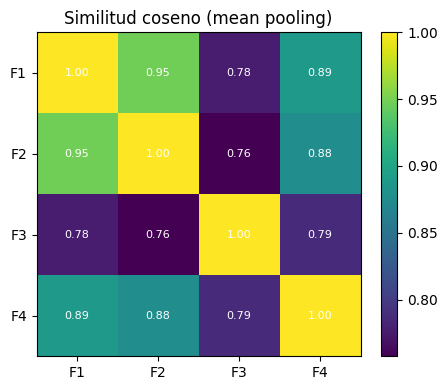

In [ ]:
frases = [
    "El celular llegó rápido y funciona perfecto.",
    "Mi teléfono nuevo llegó a tiempo y es excelente.",
    "La selección peruana ganó el partido anoche.",
    "El producto de Samsung Galaxy S21 llegó el 12 de marzo y superó mis expectativas.",
]
enc = tokenizer(frases, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
with torch.no_grad():
    last = model(**enc).last_hidden_state                        # [4, n, 768]
m = enc["attention_mask"].unsqueeze(-1).to(last.dtype)
emb = (last * m).sum(1) / m.sum(1)                               # mean pooling enmascarado
emb = torch.nn.functional.normalize(emb, dim=-1)
cos = (emb @ emb.T).cpu().numpy()

etiquetas = [f"F{i+1}" for i in range(len(frases))]
display(pd.DataFrame(cos, index=etiquetas, columns=etiquetas).round(3))
for e, f in zip(etiquetas, frases): print(e, "=", f)
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(cos, cmap="viridis"); plt.colorbar(im, fraction=.046)
ax.set_xticks(range(4)); ax.set_xticklabels(etiquetas); ax.set_yticks(range(4)); ax.set_yticklabels(etiquetas)
for i in range(4):
    for j in range(4): ax.text(j, i, f"{cos[i,j]:.2f}", ha="center", va="center", color="w", fontsize=8)
ax.set_title("Similitud coseno (mean pooling)"); plt.tight_layout(); plt.show()

**Extra B — *Fill-mask***: BETO fue preentrenado prediciendo palabras enmascaradas (MLM con *Whole Word Masking*). Usamos `BertForMaskedLM`, que añade la cabeza de predicción sobre los mismos *hidden states*.

In [ ]:
from transformers import BertForMaskedLM
try:
    mlm = BertForMaskedLM.from_pretrained(MODEL_NAME).to(device).eval()
    for frase in [f"Lima es la {tokenizer.mask_token} del Perú.",
                  f"El producto llegó muy {tokenizer.mask_token} y funciona perfecto."]:
        enc = tokenizer(frase, return_tensors="pt").to(device)
        pos = (enc["input_ids"][0] == tokenizer.mask_token_id).nonzero()[0].item()
        with torch.no_grad():
            probs = mlm(**enc).logits[0, pos].softmax(-1)
        top = torch.topk(probs, 5)
        print(frase)
        for p, i in zip(top.values.tolist(), top.indices.tolist()):
            print(f"   {tokenizer.convert_ids_to_tokens(i):15s} {p:6.1%}")
    del mlm
    if device.type == "cuda": torch.cuda.empty_cache()
except Exception as e:                      # extra opcional: no debe romper el notebook
    print("Extra B no disponible en este entorno:", repr(e))

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

Lima es la [MASK] del Perú.
   capital          98.7%
   ciudad            0.4%
   Capital           0.3%
   República         0.1%
   sede              0.1%
El producto llegó muy [MASK] y funciona perfecto.
   rápido           22.7%
   bien             20.5%
   pronto           17.2%
   lejos            16.9%
   tarde             5.2%


**Extra C — Checklist automático** de todo lo que el análisis afirma.

In [ ]:
checks = {
    "hidden_size = 768":                                   config.hidden_size == 768,
    "12 capas y 12 cabezas (d_k = 64)":                    config.num_hidden_layers == 12 and config.num_attention_heads == 12 and config.hidden_size // 12 == 64,
    "model = embeddings + encoder + pooler":               [n for n, _ in model.named_children()] == ["embeddings", "encoder", "pooler"],
    "len(hidden_states) = 13":                              len(hidden_states) == 13,
    "hidden_states[0].shape = [1, L, 768]":                 tuple(hidden_states[0].shape) == (1, len(tokens), 768),
    "attention_mask solo contiene unos (1 oración)":        bool((inputs["attention_mask"] == 1).all()),
    "token_type_ids solo contiene ceros (1 oración)":       bool((inputs["token_type_ids"] == 0).all()),
    "hidden_states[12] = last_hidden_state":                torch.allclose(hidden_states[-1], outputs.last_hidden_state, atol=1e-5),
    "Atenciones: 12 × [1, 12, L, L]":                       len(attentions) == 12 and tuple(attentions[0].shape) == (1, 12, len(tokens), len(tokens)),
    "Self-Attention propia reproduce las 12 capas de BETO": all(r[1] < 1e-3 and r[2] < 1e-3 for r in rows),
    "Cada fila de atención suma 1":                         all(torch.allclose(a.sum(-1), torch.ones_like(a.sum(-1)), atol=1e-4) for a in attentions),
}
for k, v in checks.items(): print("✅" if v else "❌", k)
assert all(checks.values()), "Alguna verificación falló"
print("\nTodas las verificaciones pasaron:", sum(checks.values()), "/", len(checks))

✅ hidden_size = 768
✅ 12 capas y 12 cabezas (d_k = 64)
✅ model = embeddings + encoder + pooler
✅ len(hidden_states) = 13
✅ hidden_states[0].shape = [1, L, 768]
✅ attention_mask solo contiene unos (1 oración)
✅ token_type_ids solo contiene ceros (1 oración)
✅ hidden_states[12] = last_hidden_state
✅ Atenciones: 12 × [1, 12, L, L]
✅ Self-Attention propia reproduce las 12 capas de BETO
✅ Cada fila de atención suma 1

Todas las verificaciones pasaron: 11 / 11


---
## ✅ Conclusiones

1. BETO es un **BERT-base** (12 capas, $d_{model}=768$, 12 cabezas de 64, FFN de 3072) con tres módulos: `embeddings`, `encoder` y `pooler`.
2. `hidden_states` tiene **13 tensores** `[1, L, 768]`: la salida de embeddings más la de cada uno de los 12 bloques; la forma nunca cambia, lo que permite las conexiones residuales.
3. El Self-Attention se reduce a $\text{softmax}(QK^T/\sqrt{d_k})V$ por cabeza; lo **implementamos desde cero y reprodujimos numéricamente** las 12 capas del modelo preentrenado.

## 📤 Entrega (guía, sección 5)

1. Verifica que **todas** las celdas tengan número de ejecución y salida visible (`Entorno de ejecución → Ejecutar todo`).
2. `Archivo → Guardar una copia en GitHub` (o `Archivo → Descargar → Descargar .ipynb` y súbelo a tu repositorio).
3. Ruta sugerida: `unidad-3-transformers/Lab03_Arquitectura_BERT_BETO.ipynb`.
4. Abre el enlace en una **ventana de incógnito** y confirma que el repositorio es **público** y que GitHub muestra las salidas y las celdas de análisis.
5. Pega el enlace directo al `.ipynb` en la tarea del aula virtual.